# Development Backtesting

## Load Backtest Inputs

- **Purpose:** Load and validate inputs for evaluating the explicitly selected Meta and Primary configurations.
- **Input:** Prepared events, split manifest, primary model, meta-model bundle, saved predictions, and market data.
- **Output:** Validated backtest inputs in memory for the following prediction, sizing, simulation, and statistics stages.
- **STRATEGY:** `market_synchronous` — Choose the matching model artifacts and execution rules.
- **PARTITION:** `development` — Use the fixed development evaluation window.
- **MANIFEST_PATH:** `data/preprocessing/universe/sp500_2025.csv` — Fix the research universe across stages.
- **RESULT_DIRECTORY:** Set the directory for saved backtest results.
- **DATA_START:** `2025-01-01 UTC` — Include January preparation observations before the research period.
- **RESEARCH_START:** `2025-02-01 UTC` — Set the inclusive research start and the first date in artifact filenames.
- **RESEARCH_END:** `2026-07-01 UTC` — Set the exclusive research end; artifact filenames use the preceding date.
- **settings:** `max_positions_per_side=10`, `initial_aum=100_000.0`, `broker_fee_bps=1.0`, `slippage_bps=1.0` — Set the total position limit per direction across both books, initial capital, and trading costs. The limit must be a positive even integer; 10 assigns 5 longs and 5 shorts to each book. Positions in the same symbol in different books count separately.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.backtesting.backtesting_workflow import (
    load_backtest_inputs, development_predictions, holdout_predictions,
    prepare_bet_sizing, simulate_portfolios, summarize_backtests, save_backtest_results,
)
from src.backtesting.portfolio_management import PortfolioSettings
from src.preprocessing.market_data import ResearchPaths

PROJECT_ROOT = Path.cwd().resolve().parents[3]

STRATEGY = "market_synchronous"
PARTITION = "development"

MANIFEST_PATH = PROJECT_ROOT / "data/preprocessing/universe/sp500_2025.csv"
RESULT_DIRECTORY = PROJECT_ROOT / "data/backtesting" / STRATEGY / "baseline" / PARTITION

DATA_START = pd.Timestamp("2025-01-01", tz="UTC")
RESEARCH_START = pd.Timestamp("2025-02-01", tz="UTC")
RESEARCH_END = pd.Timestamp("2026-07-01", tz="UTC")

settings = PortfolioSettings(
    max_positions_per_side=10,
    initial_aum=100_000.0, broker_fee_bps=1.0, slippage_bps=1.0,
)

paths = ResearchPaths(PROJECT_ROOT, model_kind="market", start=RESEARCH_START, end=RESEARCH_END)

In [2]:
inputs = load_backtest_inputs(
    paths, settings, strategy=STRATEGY, partition=PARTITION,
    manifest_path=MANIFEST_PATH,
    data_start=DATA_START, end=RESEARCH_END,
)

## Strategy Validation

- **Purpose:** Refit the explicitly selected Primary and Meta configurations within each split.
- **Input:** Development events and frozen primary/meta configurations only.
- **Output:** In-memory test-only CPCV predictions, 15 split definitions, and five complete paths for the selected model, with displayed split definitions.
- **outer_num_total_groups:** `6` — Divide development into contiguous CPCV groups.
- **outer_num_test_groups:** `2` — Hold out two groups per combination, producing 15 splits and five paths.
- **outer_pct_embargo:** `0.01` — Apply outer-fold embargo alongside purging.
- **inner_num_splits:** `5` — Generate primary OOF inputs for meta training within each outer training set.
- **inner_pct_embargo:** `0.01` — Apply embargo to inner primary OOF folds.

In [3]:
validation_settings = dict(
    outer_num_total_groups=6, outer_num_test_groups=2, outer_pct_embargo=0.01,
    inner_num_splits=5, inner_pct_embargo=0.01,
)
predictions, splits = development_predictions(inputs, **validation_settings)
display(splits.set_index("split_num")[["train_groups", "test_groups"]])

,train_groups,test_groups
split_num,,
0,"(2, 3, 4, 5)","(0, 1)"
1,"(1, 3, 4, 5)","(0, 2)"
2,"(1, 2, 4, 5)","(0, 3)"
3,"(1, 2, 3, 5)","(0, 4)"
4,"(1, 2, 3, 4)","(0, 5)"
5,"(0, 3, 4, 5)","(1, 2)"
6,"(0, 2, 4, 5)","(1, 3)"
7,"(0, 2, 3, 5)","(1, 4)"
8,"(0, 2, 3, 4)","(1, 5)"


## Bet Sizing

- **Purpose:** Select the latest eligible signal per symbol and rank take probabilities at scheduled open/close entries, with a one-minute information cutoff.
- **Input:** Family/path predictions and the session entry/exit schedule.
- **Output:** In-memory selections with equal weights within each side (half the book per side); exclude entries without an exit inside evaluation bounds.

In [4]:
prepared = prepare_bet_sizing(inputs, predictions, splits)

## Portfolio Management

- **Purpose:** Execute independent family/path accounts using a shared price index and scheduled decisions/fills.
- **Input:** Prepared signals/calibration and existing dollar bars.
- **Output:** In-memory ledgers, trades, exposures, and exclusions.


In [5]:
accounts = simulate_portfolios(inputs, prepared, show_progress=True)

Preparing synchronous price index


Synchronous decisions:   0%|          | 0/459 [00:00<?, ?decision/s]

## Backtest Statistics

- **Purpose:** Summarize account, classification, and holding metrics without resimulating.
- **Input:** Existing accounts, out-of-sample predictions, and returns for the selected benchmark symbol.
- **Output:** One selected-model statistics table and one cumulative-return graph; save `statistics.parquet` and `settings.json` under `RESULT_DIRECTORY`.
- **benchmark_symbol:** `SPY` — Select the market benchmark; local dollar bars must cover the evaluation interval and provide a starting anchor.
- **periods_per_year:** `365.25` — Annualize the calendar-day account series.
- **annual_risk_free_rate:** `0.03` — Use the assumed annual risk-free rate in risk-adjusted statistics.
- **annualized_benchmark_sharpe_ratio:** `1.0` — Set the reference Sharpe for probabilistic Sharpe evaluation.

In [6]:
evaluation_settings = dict(
    benchmark_symbol="SPY",
    periods_per_year=365.25, annual_risk_free_rate=0.03,
    annualized_benchmark_sharpe_ratio=1.0,
)

statistics = summarize_backtests(inputs, predictions, accounts, **evaluation_settings)

### Random Forest: Backtest Statistics

path_0  \
section                  metric                          unit                                           
general_characteristics  start                           timestamp   2025-02-03T14:30:00.019529+00:00   
                         end                             timestamp          2025-12-31T21:00:00+00:00   
                         average_aum                     USD                        99531.53930051156   
                         leverage                        ratio                    0.48418321202963505   
                         maximum_dollar_position_size    USD                        56128.83352249372   
                         ratio_of_longs                  ratio                     0.5300546448087432   
                         frequency_of_bets               count/year                2219.4777702081697   
                         average_holding_period          days                      1.4506371385267638   
                         annualized_turnover             ratio                     244.58169810458776   
                         correlation_to_underlying       ratio                    0.32174937955091504   
performance              pnl                             USD                        4146.973174803337   
                         annualized_rate_of_return       ratio                    0.04581943415583489   
                         pnl_from_long_positions         USD                       2190.4759348848183   
                         pnl_from_short_positions        USD                         1956.49723991855   
                         hit_ratio                       ratio                      0.503725782414307   
                         average_return_from_hits        ratio                   0.001831662898418804   
                         average_return_from_misses      ratio                 -0.0017722303599425893   
runs                     hhi_positive_returns            ratio                  0.0012807028910907605   
                         hhi_negative_returns            ratio                   0.001164031639032512   
                         hhi_time_between_bets           ratio                  0.0008740997722454194   
                         percentile_drawdown             ratio                   0.013652284549920433   
                         percentile_time_under_water     years                    0.06345536611727766   
implementation_shortfall broker_fees_per_turnover        ratio                  9.999999612174888e-05   
                         average_slippage_per_turnover   ratio                  9.999999999999954e-05   
                         dollar_performance_per_turnover ratio                 0.00018782507640185362   
                         return_on_execution_costs       ratio                      0.939125400220091   
efficiency               sharpe_ratio                    ratio                   0.014752339967229538   
                         annualized_sharpe_ratio         ratio                    0.28193956440930606   
                         probabilistic_sharpe_ratio      ratio                     0.2452825147726977   
classification_scores    primary_accuracy                score                     0.6026490003875908   
                         primary_precision_-1            score                     0.5842224045986742   
                         primary_recall_-1               score                     0.6199702648558978   
                         primary_f1_-1                   score                     0.6015657263182725   
                         primary_precision_1             score                     0.6220938309873232   
                         primary_recall_1                score                     0.5864124675322457   
                         primary_f1_1                    score                     0.6037263999579509   
                         primary_balanced_accuracy       score                     0.6031913661940718   


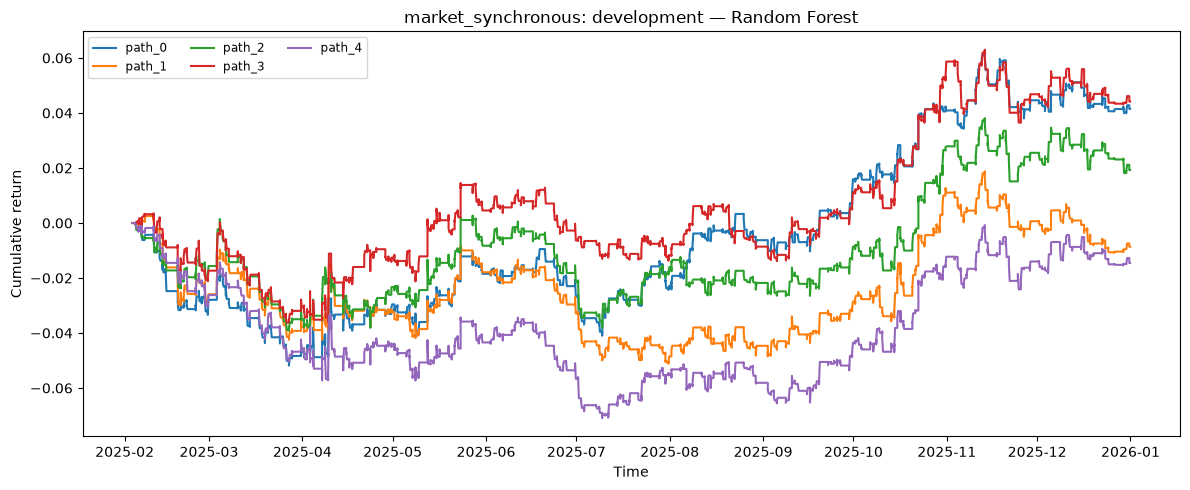

In [7]:
from IPython.display import Markdown

for family in statistics["model_family"].drop_duplicates():
    family_name = family.replace("_", " ").title()
    family_statistics = statistics.loc[statistics["model_family"].eq(family)].set_index(
        ["section", "metric", "unit"],
    )
    display_values = family_statistics.drop(columns="model_family")
    display(Markdown(f"### {family_name}: Backtest Statistics"))
    with pd.option_context(
        "display.max_rows", None, "display.max_columns", None,
        "display.max_colwidth", None,
    ):
        display(display_values)

    fig, ax = plt.subplots(figsize=(12, 5))
    for (account_family, path), result in accounts.items():
        if account_family == family:
            ledger = result["ledger"]
            ax.plot(ledger.timestamp, ledger.aum / settings.initial_aum - 1, label=path)
    ax.set(
        title=f"{STRATEGY}: {PARTITION} — {family_name}",
        ylabel="Cumulative return", xlabel="Time",
    )
    ax.legend(fontsize="small", ncol=3)
    fig.tight_layout()
    plt.show()

In [8]:
result_directory = save_backtest_results(
    inputs, statistics,
    evaluation_settings=evaluation_settings, validation_settings=validation_settings,
    result_directory=RESULT_DIRECTORY,
)
print(result_directory)

/Users/kwonjunhyuk9/Documents/financial-machine-learning/data/backtesting/market_synchronous/development
